# Шаг 3. Точка отсчёта: полносвязная сеть из сессии 3

Прежде чем строить свёрточную сеть, проверим, как справится уже знакомая **полносвязная** (MLP).
Это наша **точка отсчёта** (baseline): у любой новой идеи должно получаться лучше.

Сеть та же, что в сессии 3, только вход больше: `3 · 32 · 32 = 3072` числа → 256 → 64 → **2 выхода** (кошка и собака).

Следим за **двумя** точностями после каждой эпохи:
- **на обучающих** картинках — на тех, что сеть видит и по которым подправляет веса;
- **на проверочных** — на тех, что она не видела никогда. Только эта точность говорит, чему сеть **научилась**, а не что **запомнила**.

**Структура примера (алгоритм):**
1. Загружаем данные, фиксируем случайность.
2. Создаём MLP и считаем веса.
3. Обучаем 8 эпох, после каждой — две точности.
4. Сохраняем историю обучения в `mlp.json` и рисуем графики.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Данные и сеть

`torch.manual_seed(0)` — одинаковые начальные веса и порядок картинок при каждом запуске.
Из 3072 · 256 весов первого слоя состоит основная часть сети — это почти 800 тысяч чисел.

In [1]:
import matplotlib.pyplot as plt
import torch

from common import MLP, CatsDogs, count_params, save_model, show, train

torch.manual_seed(0)
train_set, test_set = CatsDogs(train=True), CatsDogs(train=False)

model = MLP()
print(model)
print("Весов в сети:", count_params(model))

MLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)
Весов в сети: 803266


## 2. Обучение

Функция `train` из `common.py` — тот же цикл, что в сессии 3 (посмотреть → ошибка → `backward` → `step`),
плюс подсчёт точности на обучающих картинках прямо во время эпохи и на проверочных — после неё.
Обучение займёт несколько секунд.

In [4]:
history = train(model, train_set, test_set, epochs=20)
save_model(model, "mlp", history)

Эпоха  1: на обучающих 61.6%, на проверочных 61.5%
Эпоха  2: на обучающих 62.1%, на проверочных 61.4%
Эпоха  3: на обучающих 62.2%, на проверочных 61.3%
Эпоха  4: на обучающих 62.4%, на проверочных 58.9%
Эпоха  5: на обучающих 63.4%, на проверочных 61.7%
Эпоха  6: на обучающих 63.6%, на проверочных 59.9%
Эпоха  7: на обучающих 63.0%, на проверочных 62.1%
Эпоха  8: на обучающих 63.3%, на проверочных 61.2%
Эпоха  9: на обучающих 64.3%, на проверочных 61.3%
Эпоха 10: на обучающих 64.8%, на проверочных 60.7%
Эпоха 11: на обучающих 64.4%, на проверочных 62.6%
Эпоха 12: на обучающих 65.0%, на проверочных 62.8%
Эпоха 13: на обучающих 65.3%, на проверочных 61.3%
Эпоха 14: на обучающих 65.9%, на проверочных 61.8%
Эпоха 15: на обучающих 65.0%, на проверочных 61.9%
Эпоха 16: на обучающих 66.3%, на проверочных 62.6%
Эпоха 17: на обучающих 66.8%, на проверочных 61.9%
Эпоха 18: на обучающих 66.8%, на проверочных 61.9%
Эпоха 19: на обучающих 67.0%, на проверочных 58.1%
Эпоха 20: на обучающих 67.0%, н

## 3. Графики

Ожидаемая картина: обе линии быстро поднимаются до **~60%** и там **застревают** —
лишь немного лучше подбрасывания монетки (50%). При этом у сети 800 тысяч весов!

Важно, что сеть плохо справляется **даже с обучающими** картинками — теми, которые она видит снова и снова.
Значит, дело не в нехватке данных, а в **архитектуре**: полносвязная сеть не знает, что соседние пиксели связаны,
и не умеет узнавать один и тот же узор в разных местах кадра. Ей остаётся опираться на грубые признаки
вроде «в среднем на фото больше коричневого», а этого мало.

> Если учить её очень долго (50+ эпох), точность на обучающих поползёт вверх, а на проверочных — нет:
> сеть начнёт просто запоминать конкретные фото. Это называется **переобучение** — о нём подробнее в шаге 4.

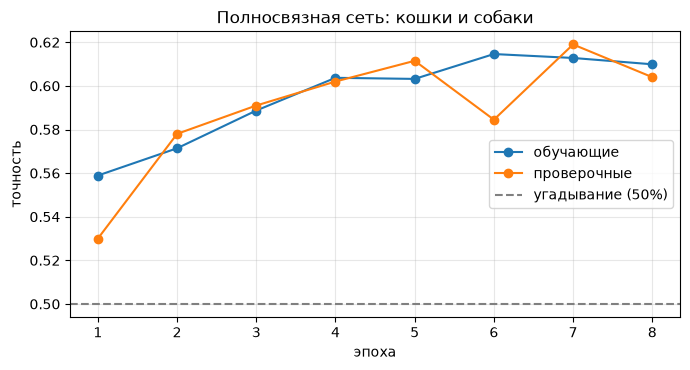

In [3]:
epochs = range(1, len(history["train"]) + 1)
plt.figure(figsize=(7, 3.8))
plt.plot(epochs, history["train"], "o-", label="обучающие")
plt.plot(epochs, history["test"], "o-", label="проверочные")
plt.axhline(0.5, color="gray", linestyle="--", label="угадывание (50%)")
plt.xlabel("эпоха")
plt.ylabel("точность")
plt.title("Полносвязная сеть: кошки и собаки")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_curves.png", dpi=100)
show()

## Попробуйте сами

1. Увеличьте число эпох до 20. Что происходит с разрывом между двумя графиками?
2. Сделайте сеть шире: 1024 нейрона в первом слое (в `common.py`). Помогает ли это на проверке?
3. Повторите эксперимент с перемешанными пикселями из сессии 3. Станет ли MLP хуже? А как вы думаете, что будет со свёрточной сетью?